# <center>Emotion Prediction from English Comments – Comparison of Machine Learning Algorithms</center>

## Introduction - A Multi-class Classification Problem
##### **Definition:** Emotion detection is the task of identifying the emotion (e.g., joy, sadness, anger, fear) expressed by a person in a piece of text using natural language processing and machine learning techniques. Each comment belongs to exactly **one** of several emotion classes, so it is a **multi-class classification** problem.
##### **Applications:** Applications of emotion detection include customer-support prioritisation (angry customers first), mental-health monitoring, analysing reactions to products and events on social media, chatbots that respond with empathy, and market research.

## Input & Output

##### **Input:** An English comment
##### **Output:** Predicted emotion label (Sadness / Joy / Love / Anger / Fear / Surprise)

## Examples (Emotion Dataset)

| **Sr. No** | **Comment (Input)**                                         | **Emotion (Output)** |
| ---------- | ----------------------------------------------------------- | -------------------- |
| 1          | I feel so lonely since my best friend moved away.           | Sadness              |
| 2          | I am feeling really excited about my results today.         | Joy                  |
| 3          | I feel so lucky and loved to have such a caring family.     | Love                 |
| 4          | I feel furious that they cancelled my order without asking. | Anger                |
| 5          | I feel nervous and scared about tomorrow's exam.            | Fear                 |
| 6          | I was amazed when I saw the result, it was so unexpected.   | Surprise             |

## Developer and System Information

| **Field**                     | **Details**                                                                 |
|-------------------------------|-------------------------------------------------------------------------|
| **Developer Name**            | Haq Nawaz; Dr. Rao Muhammad Adeel Nawab                                 |
| **LinkedIn (Haq Nawaz)**      | https://www.linkedin.com/in/haqnawaz99/                                 |
| **LinkedIn (Dr. Rao Muhammad Adeel Nawab)** | https://www.linkedin.com/in/rao-muhammad-adeel-nawab/?trk=feed_main-feed-card_feed-actor-name |
| **Program Name**              | emotion_prediction_algorithm_comparison                                 |
| **IDE**                       | Jupyter Notebook / Google Colab                                         |
| **Programming Language**      | Python 3.10                                                             |
| **Operating System**          | Windows 11                                                              |
| **Libraries**                 | pandas 2.3.3, numpy, matplotlib 3.10, seaborn 0.13.2, scikit-learn 1.7.2, joblib 1.6.0 |
| **Date of Completion**        | 10-Nov-2026                                                              |
| **Website**                   | www.ilmoirfan.com; www.ilmoirfan.ai                                      |
| **Email**                     | info@ilmoirfan.com; info@ilmoirfan.ai                                    |

## Table of Content

- *Step 1:* Import Libraries

- *Step 2:* Load Sample Data (emotion_sample_data.csv)
  - Step 2.1: View Shape and First Rows of the Dataset
  - Step 2.2: Count Number of Instances for Each Emotion

- *Step 3:* Data Cleaning and Preprocessing
  - Step 3.1: Set Stopwords
  - Step 3.2: Write Functions to Clean Text
  - Step 3.3: Drop Rows with NaN Values in Text Column
  - Step 3.4: Apply Functions to Clean Text
  - Step 3.5: Data After Cleaning and Preprocessing
  - Step 3.6: Save Cleaned Data as Separate CSV File (called clean_emotion_sample_data.csv)

- *Step 4:* Split Sample Data into Training and Testing Sets (80% / 20%, Stratified)

- *Step 5:* Feature Extraction from Text (using TF-IDF Vectorizer)
  - Step 5.1: Train tfidf_vectorizer using Training Data
  - Step 5.2: Transform Training Text into Feature Vectors using tfidf_vectorizer (trained in Step 5.1)
  - Step 5.3: Transform Testing Text into Feature Vectors using tfidf_vectorizer (trained in Step 5.1)
  - Step 5.4: Save tfidf_vectorizer

- *Step 6:* Execute the Training Phase
  - Step 6.1: Select Machine Learning Algorithms
  - Step 6.2: Train All Models (using Training Feature Vectors created in Step 5.2)
  - Step 6.3: Save All Trained Models

- *Step 7:* Execute the Testing Phase
  - Step 7.1: Load All Trained Models (saved in Step 6.3)
  - Step 7.2: Evaluate All Trained Models (using Testing Feature Vectors created in Step 5.3)
  - Step 7.3: Display Confusion Matrix of Each Algorithm

- *Step 8:* Compare the Algorithms
  - Step 8.1: Comparison Table (sorted by F1-Score)
  - Step 8.2: Comparison Bar Chart
  - Step 8.3: Select and Save the Best Model
  - Step 8.4: Detailed Classification Report of the Best Model

- *Step 9:* Execute the Application Phase
  - Step 9.1: Load tfidf_vectorizer (saved in Step 5.4)
  - Step 9.2: Load the Best Model (saved in Step 8.3)
  - Step 9.3: Take Input from User
  - Step 9.4: Clean and Preprocess User Input (exactly as you did for Sample Data in Step 3)
  - Step 9.5: Apply tfidf_vectorizer to Cleaned and Preprocessed User Input
  - Step 9.6: Model Prediction

- *Step 10:* Execute the Feedback Phase

- *Conclusion*

## Data - Download Link
##### https://huggingface.co/datasets/dair-ai/emotion
##### **Source:** Saravia et al. (2018), *CARER: Contextualized Affect Representations for Emotion Recognition*, EMNLP. English Twitter messages labelled with six emotions (for educational and research use).
##### **Sample Data used in this notebook (emotion_sample_data.csv):** 2,400 comments taken from the training split of the dataset – duplicate comments removed, then **400 comments for each of the 6 emotions** (balanced), selected randomly with random_state = 42.

## Code – Emotion Prediction from English Comments

### Data Collection and Data Understanding

### Step 1: Import Libraries

In [1]:
# Regular expressions library for text cleaning (e.g., removing special characters, numbers)
import re

# Time library to measure how long each algorithm takes to train
import time

# Pandas for loading and manipulating datasets (DataFrame structure)
import pandas as pd

# Matplotlib and Seaborn for plots (count plot, confusion matrices, bar chart)
import matplotlib.pyplot as plt
import seaborn as sns

# Joblib to save and load trained models
import joblib

# Built-in English stopwords list of scikit-learn (no internet download needed)
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# TF-IDF Vectorizer converts text into numerical feature vectors
from sklearn.feature_extraction.text import TfidfVectorizer

# Splits the dataset into training and testing sets
from sklearn.model_selection import train_test_split

# Machine Learning Algorithms (6 algorithms to compare)
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

### Step 2: Load Sample Data (emotion_sample_data.csv)

In [2]:
# In Google Colab: upload emotion_sample_data.csv from your computer.
# On your own computer (Jupyter): the file is read from the same folder as this notebook.
try:
    from google.colab import files
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
except ImportError:
    file_name = "emotion_sample_data.csv"

# Load the dataset into a pandas DataFrame (columns: Comment, Emotion)
data = pd.read_csv(file_name)

print("\n\nEmotion Sample Data:")
print("====================\n")
print("File name =", file_name)



Emotion Sample Data:

File name = emotion_sample_data.csv


#### Step 2.1: View Shape and First Rows of the Dataset

In [3]:
# Shape = (number of rows, number of columns)
print("Shape of the dataset =", data.shape)
print("Columns in the dataset =", list(data.columns))
print()

# Show the first 10 comments with their emotion
data.head(10)

Shape of the dataset = (2400, 2)
Columns in the dataset = ['Comment', 'Emotion']



,Comment,Emotion
0,im feeling really weird,surprise
1,i could find another reason i m new in the are...,fear
2,im feeling like life is fairly sweet,love
3,i know at this point is im starting to feel do...,fear
4,i feel a strange sense of legacy,surprise
5,i still love my so and wish the best for him i...,sadness
6,i feel a mad connection with your body and thi...,anger
7,i can t get past is that feeling when a friend...,fear
8,i feel like we just rushed around trying to se...,anger
9,im writing again but feel like discarding it b...,love


#### Step 2.2: Count Number of Instances for Each Emotion

In [4]:
# Count the number of unique emotion labels in the dataset
num_labels = data['Emotion'].nunique()
print(f"Number of unique emotion labels: {num_labels}")

# Count the number of instances for each emotion label
print("\nNumber of instances for each emotion:")
print(data['Emotion'].value_counts())

Number of unique emotion labels: 6

Number of instances for each emotion:
Emotion
surprise    400
fear        400
love        400
sadness     400
anger       400
joy         400
Name: count, dtype: int64


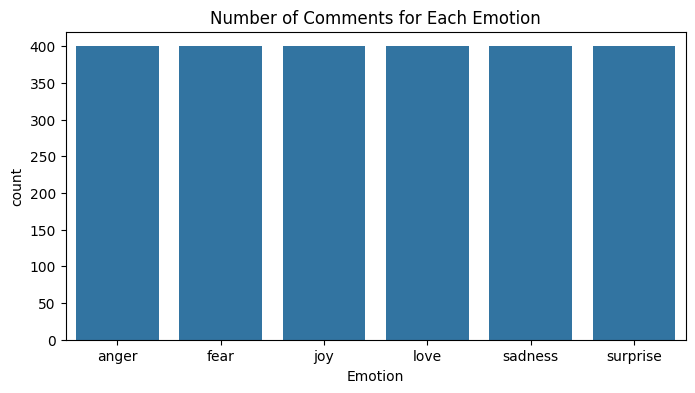

In [5]:
# Plot the number of instances for each emotion (the data is balanced: 400 each)
plt.figure(figsize=(8, 4))
sns.countplot(x='Emotion', data=data, order=sorted(data['Emotion'].unique()))
plt.title("Number of Comments for Each Emotion")
plt.show()

### Step 3: Data Cleaning and Preprocessing

#### Step 3.1: Set Stopwords

In [6]:
# Stopwords are very common words (e.g., "the", "is", "and") that carry little meaning.
# We use the built-in English stopwords list of scikit-learn.
stop_words = set(ENGLISH_STOP_WORDS)

print("Number of stopwords =", len(stop_words))
print("Some stopwords:", sorted(stop_words)[:20])

Number of stopwords = 318
Some stopwords: ['a', 'about', 'above', 'across', 'after', 'afterwards', 'again', 'against', 'all', 'almost', 'alone', 'along', 'already', 'also', 'although', 'always', 'am', 'among', 'amongst', 'amoungst']


#### Step 3.2: Write Functions to Clean Text

#### Function 1: Remove Symbols and Numbers

In [7]:
def remove_symbols_and_numbers(text):
    # Keep only English letters and spaces (remove digits, punctuation, emojis, etc.)
    return re.sub(r'[^a-zA-Z\s]', '', text)

#### Function 2: Convert Text to Lowercase

In [8]:
def convert_to_lowercase(text):
    # Convert all characters to lowercase so that "Happy" and "happy" are the same word
    return text.lower()

#### Function 3: Remove Stopwords

In [9]:
def remove_stopwords(text):
    # Split the text into words, keep only the words that are not stopwords, join them back
    return ' '.join(word for word in text.split() if word not in stop_words)

#### Function 4: Complete Cleaning (all three functions together)

In [10]:
def clean_text(text):
    # Apply the three cleaning functions one after the other
    text = remove_symbols_and_numbers(text)
    text = convert_to_lowercase(text)
    text = remove_stopwords(text)
    return text

#### Step 3.3: Drop Rows with NaN Values in Text Column

In [11]:
# Remove rows where the comment is missing
print("Rows before dropping NaN =", len(data))
data = data.dropna(subset=['Comment']).reset_index(drop=True)
print("Rows after dropping NaN  =", len(data))

Rows before dropping NaN = 2400
Rows after dropping NaN  = 2400


#### Step 3.4: Apply Functions to Clean Text

In [12]:
# Keep a copy of the original comment so that we can compare before and after cleaning
data['Original_Comment'] = data['Comment']

# Apply the complete cleaning function to every comment
data['Comment'] = data['Comment'].apply(clean_text)

# Compare a few comments before and after cleaning
print("\nBefore and After Cleaning:")
print("==========================\n")
for i in range(5):
    print("Before :", data.loc[i, 'Original_Comment'])
    print("After  :", data.loc[i, 'Comment'])
    print()


Before and After Cleaning:

Before : im feeling really weird
After  : im feeling really weird

Before : i could find another reason i m new in the area and i feel less intimidated with a simple tool that i can understand
After  : reason m new area feel intimidated simple tool understand

Before : im feeling like life is fairly sweet
After  : im feeling like life fairly sweet

Before : i know at this point is im starting to feel doubtful of the decisions i made
After  : know point im starting feel doubtful decisions

Before : i feel a strange sense of legacy
After  : feel strange sense legacy



#### Step 3.5: Data After Cleaning and Preprocessing

In [13]:
# Remove the helper column and any comment that became empty after cleaning
data = data.drop(columns=['Original_Comment'])
data = data[data['Comment'].str.strip() != ''].reset_index(drop=True)

print("\n\nEmotion Data After Preprocessing:")
print("=================================\n")
print("Shape of the cleaned dataset =", data.shape)
data.head(10)



Emotion Data After Preprocessing:

Shape of the cleaned dataset = (2400, 2)


,Comment,Emotion
0,im feeling really weird,surprise
1,reason m new area feel intimidated simple tool...,fear
2,im feeling like life fairly sweet,love
3,know point im starting feel doubtful decisions,fear
4,feel strange sense legacy,surprise
5,love wish best longer tolerate effect bm lives...,sadness
6,feel mad connection body decided kick,anger
7,t past feeling friend walks life unsure feelin...,fear
8,feel like just rushed trying things quite beau...,anger
9,im writing feel like discarding lack supportin...,love


#### Step 3.6: Save Cleaned Data as Separate CSV File (called clean_emotion_sample_data.csv)

In [14]:
data.to_csv("clean_emotion_sample_data.csv", index=False)
print("Cleaned data saved as 'clean_emotion_sample_data.csv'")

Cleaned data saved as 'clean_emotion_sample_data.csv'


### Step 4: Split Sample Data into Training and Testing Sets (80% / 20%, Stratified)

##### stratify = y keeps the same proportion of each emotion in both sets (each emotion gets 80% training and 20% testing comments).

In [15]:
# Features (X) = cleaned comment, Label (y) = emotion
X = data['Comment']
y = data['Emotion']

# 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Number of training comments =", len(X_train))
print("Number of testing comments  =", len(X_test))

# Number of comments of each emotion in training and testing sets
split_counts = pd.DataFrame({
    'Training': y_train.value_counts(),
    'Testing':  y_test.value_counts()
})
print("\nComments per emotion in each set:")
print(split_counts)

Number of training comments = 1920
Number of testing comments  = 480

Comments per emotion in each set:
          Training  Testing
Emotion                    
anger          320       80
fear           320       80
joy            320       80
love           320       80
sadness        320       80
surprise       320       80


### Step 5: Feature Extraction from Text (using TF-IDF Vectorizer)

##### **max_features = 2000:** only the 2000 most frequent words of the training data are used as features. Very few features (e.g., 10) make most comments all zeros; using every word adds many rare words that appear only once.

#### Step 5.1: Train tfidf_vectorizer using Training Data

In [16]:
# Create the TF-IDF vectorizer with the 2000 most frequent words
tfidf_vectorizer = TfidfVectorizer(max_features=2000)

# Learn the vocabulary from the TRAINING comments only
tfidf_vectorizer.fit(X_train)

print("Number of features (words) =", len(tfidf_vectorizer.get_feature_names_out()))
print("Some features:", list(tfidf_vectorizer.get_feature_names_out()[:20]))

Number of features (words) =

 2000
Some features: ['abide', 'abilities', 'ability', 'able', 'abraham', 'abroad', 'absolutely', 'abstain', 'abundantly', 'abused', 'abusive', 'accept', 'acceptable', 'acceptance', 'accepted', 'accident', 'accidentally', 'accomplished', 'achieved', 'aching']


#### Step 5.2: Transform Training Text into Feature Vectors using tfidf_vectorizer (trained in Step 5.1)

In [17]:
X_train_tfidf = tfidf_vectorizer.transform(X_train)
print("Shape of training feature vectors =", X_train_tfidf.shape)

Shape of training feature vectors = (1920, 2000)


#### Step 5.3: Transform Testing Text into Feature Vectors using tfidf_vectorizer (trained in Step 5.1)

In [18]:
X_test_tfidf = tfidf_vectorizer.transform(X_test)
print("Shape of testing feature vectors =", X_test_tfidf.shape)

# Show the feature vectors of the first 5 testing comments (only the first 10 columns)
X_test_tfidf_df = pd.DataFrame(
    X_test_tfidf.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out()
)
X_test_tfidf_df.iloc[:5, :10]

Shape of testing feature vectors = (480, 2000)


,abide,abilities,ability,able,abraham,abroad,absolutely,abstain,abundantly,abused
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### Step 5.4: Save tfidf_vectorizer

In [19]:
joblib.dump(tfidf_vectorizer, 'tfidf_vectorizer.pkl')
print("tfidf_vectorizer saved as 'tfidf_vectorizer.pkl'")

tfidf_vectorizer saved as 'tfidf_vectorizer.pkl'


### Step 6: Execute the Training Phase

#### Step 6.1: Select Machine Learning Algorithms

| **Sr. No** | **Algorithm**                | **Idea in one line**                                                   |
| ---------- | ---------------------------- | ---------------------------------------------------------------------- |
| 1          | Multinomial Naive Bayes      | Uses word probabilities for each emotion (Bayes theorem)               |
| 2          | Logistic Regression          | Learns a weight for every word and emotion                              |
| 3          | Linear SVM                   | Finds the best separating boundary between the emotions                |
| 4          | K-Nearest Neighbors          | Looks at the 5 most similar training comments                          |
| 5          | Decision Tree                | Asks a series of yes/no questions about words                          |
| 6          | Random Forest                | Many decision trees vote together                                       |

In [20]:
# Dictionary: algorithm name -> algorithm object
algorithms = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression":     LogisticRegression(max_iter=1000, random_state=42),
    "Linear SVM":              LinearSVC(random_state=42),
    "K-Nearest Neighbors":     KNeighborsClassifier(n_neighbors=5),
    "Decision Tree":           DecisionTreeClassifier(random_state=42),
    "Random Forest":           RandomForestClassifier(n_estimators=100, random_state=42),
}

print("Algorithms selected:")
for name in algorithms:
    print(" -", name)

Algorithms selected:
 - Multinomial Naive Bayes
 - Logistic Regression
 - Linear SVM
 - K-Nearest Neighbors
 - Decision Tree
 - Random Forest


#### Step 6.2: Train All Models (using Training Feature Vectors created in Step 5.2)

In [21]:
training_times = {}

for name, model in algorithms.items():
    start = time.time()
    # Train the model on the training feature vectors and training labels
    model.fit(X_train_tfidf, y_train)
    training_times[name] = time.time() - start
    print(f"{name:<25} trained in {training_times[name]:.2f} seconds")

Multinomial Naive Bayes   trained in 0.01 seconds


Logistic Regression       trained in 0.37 seconds
Linear SVM                trained in 0.06 seconds
K-Nearest Neighbors       trained in 0.01 seconds


Decision Tree             trained in 0.61 seconds


Random Forest             trained in 2.93 seconds


#### Step 6.3: Save All Trained Models

In [22]:
# Each model is saved in its own file, e.g. 'Logistic_Regression_model.pkl'
model_files = {}
for name, model in algorithms.items():
    file_name = name.replace(" ", "_").replace("-", "_") + "_model.pkl"
    joblib.dump(model, file_name)
    model_files[name] = file_name
    print(f"{name:<25} saved as '{file_name}'")

Multinomial Naive Bayes   saved as 'Multinomial_Naive_Bayes_model.pkl'
Logistic Regression       saved as 'Logistic_Regression_model.pkl'
Linear SVM                saved as 'Linear_SVM_model.pkl'
K-Nearest Neighbors       saved as 'K_Nearest_Neighbors_model.pkl'
Decision Tree             saved as 'Decision_Tree_model.pkl'
Random Forest             saved as 'Random_Forest_model.pkl'


### Step 7: Execute the Testing Phase

#### Step 7.1: Load All Trained Models (saved in Step 6.3)

In [23]:
loaded_models = {}
for name, file_name in model_files.items():
    loaded_models[name] = joblib.load(file_name)
    print(f"{name:<25} loaded from '{file_name}'")

Multinomial Naive Bayes   loaded from 'Multinomial_Naive_Bayes_model.pkl'


Logistic Regression       loaded from 'Logistic_Regression_model.pkl'
Linear SVM                loaded from 'Linear_SVM_model.pkl'
K-Nearest Neighbors       loaded from 'K_Nearest_Neighbors_model.pkl'
Decision Tree             loaded from 'Decision_Tree_model.pkl'


Random Forest             loaded from 'Random_Forest_model.pkl'


#### Step 7.2: Evaluate All Trained Models (using Testing Feature Vectors created in Step 5.3)

##### For multi-class problems, precision, recall and F1-Score are calculated for every emotion and then averaged (**macro average** = every emotion counts equally).

In [24]:
results = []
predictions = {}

for name, model in loaded_models.items():
    # Predict the emotion of every testing comment
    y_pred = model.predict(X_test_tfidf)
    predictions[name] = y_pred

    results.append({
        'Algorithm': name,
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Recall':    recall_score(y_test, y_pred, average='macro', zero_division=0),
        'F1-Score':  f1_score(y_test, y_pred, average='macro', zero_division=0),
        'Training Time (s)': training_times[name],
    })

results_df = pd.DataFrame(results)
print("\nEvaluation Metrics (Testing Data):")
print("==================================\n")
results_df.round(4)


Evaluation Metrics (Testing Data):



,Algorithm,Accuracy,Precision,Recall,F1-Score,Training Time (s)
0,Multinomial Naive Bayes,0.7062,0.7072,0.7062,0.6976,0.0148
1,Logistic Regression,0.7812,0.7799,0.7812,0.7768,0.3748
2,Linear SVM,0.7854,0.7817,0.7854,0.7805,0.0567
3,K-Nearest Neighbors,0.5583,0.6312,0.5583,0.5533,0.0055
4,Decision Tree,0.7438,0.7415,0.7437,0.7398,0.6075
5,Random Forest,0.7771,0.7809,0.7771,0.7754,2.9300


#### Step 7.3: Display Confusion Matrix of Each Algorithm

##### Rows = actual emotion, columns = predicted emotion. The diagonal shows correct predictions (80 testing comments per emotion).

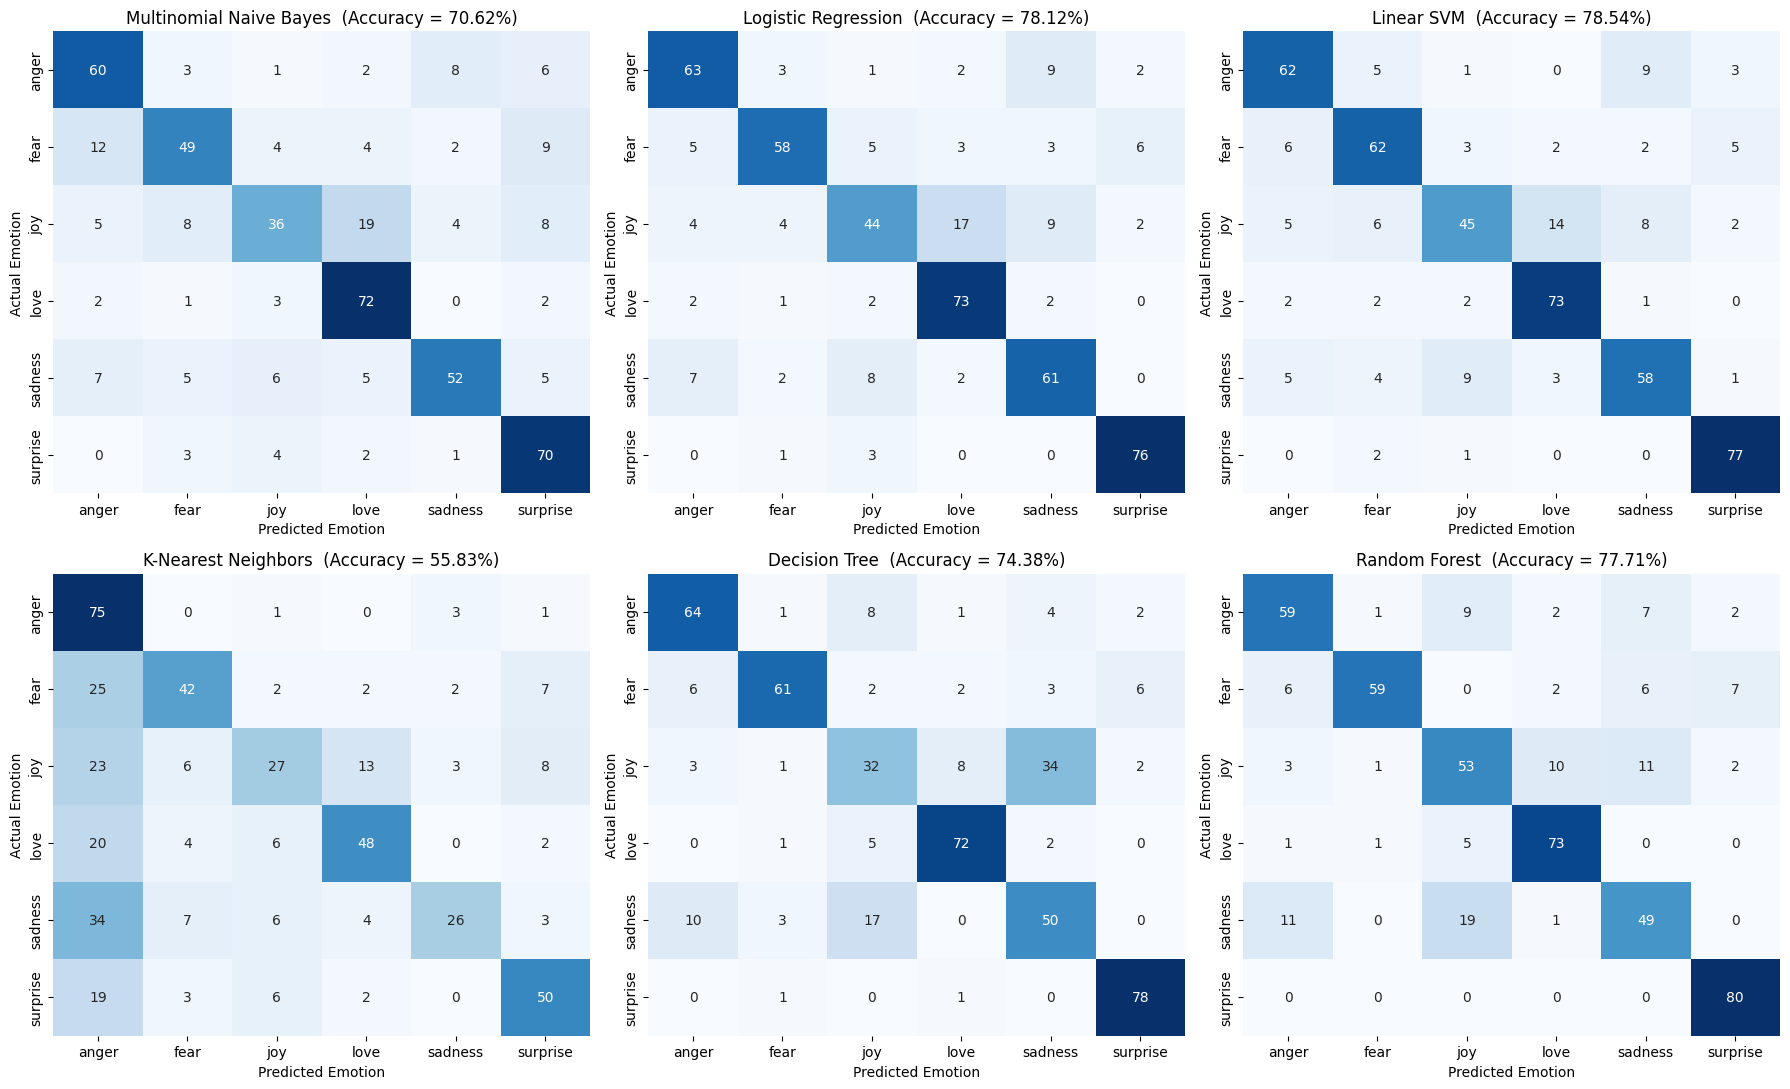

In [25]:
emotion_labels = sorted(y.unique())

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=emotion_labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=emotion_labels, yticklabels=emotion_labels, ax=ax)
    acc = accuracy_score(y_test, y_pred)
    ax.set_title(f"{name}  (Accuracy = {acc:.2%})")
    ax.set_xlabel("Predicted Emotion")
    ax.set_ylabel("Actual Emotion")
plt.tight_layout()
plt.show()

### Step 8: Compare the Algorithms

#### Step 8.1: Comparison Table (sorted by F1-Score)

In [26]:
comparison = results_df.sort_values('F1-Score', ascending=False).reset_index(drop=True)
comparison.index = comparison.index + 1          # rank starts from 1
comparison.index.name = 'Rank'

print("\nComparison of Algorithms:")
print("=========================\n")
comparison.round(4)


Comparison of Algorithms:



,Algorithm,Accuracy,Precision,Recall,F1-Score,Training Time (s)
Rank,,,,,,
1,Linear SVM,0.7854,0.7817,0.7854,0.7805,0.0567
2,Logistic Regression,0.7812,0.7799,0.7812,0.7768,0.3748
3,Random Forest,0.7771,0.7809,0.7771,0.7754,2.9300
4,Decision Tree,0.7438,0.7415,0.7437,0.7398,0.6075
5,Multinomial Naive Bayes,0.7062,0.7072,0.7062,0.6976,0.0148
6,K-Nearest Neighbors,0.5583,0.6312,0.5583,0.5533,0.0055


#### Step 8.2: Comparison Bar Chart

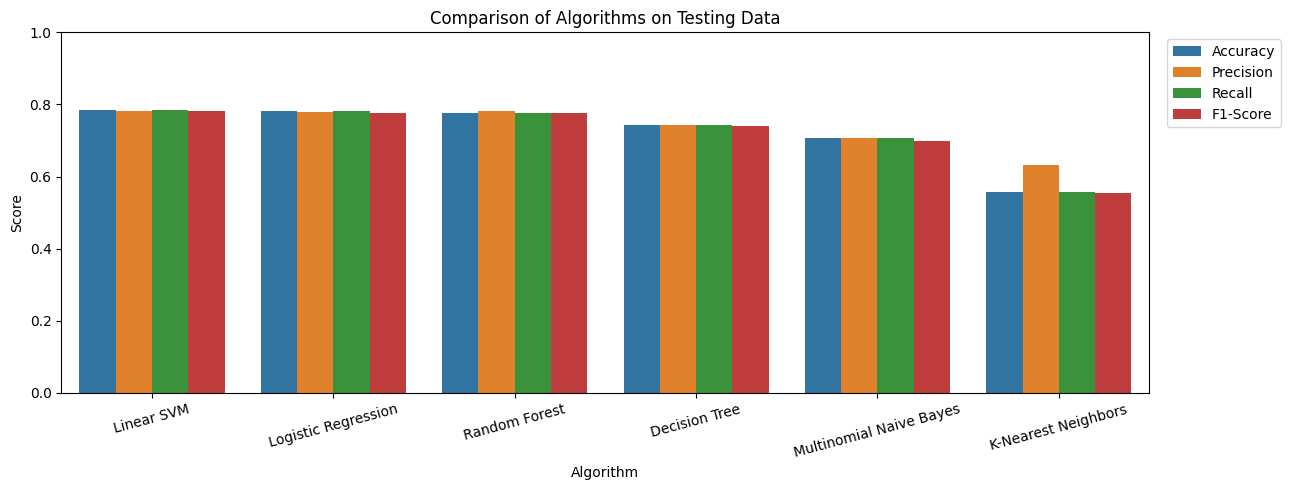

In [27]:
plot_df = comparison.melt(id_vars='Algorithm',
                          value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score'],
                          var_name='Metric', value_name='Score')

plt.figure(figsize=(13, 5))
sns.barplot(data=plot_df, x='Algorithm', y='Score', hue='Metric')
plt.title("Comparison of Algorithms on Testing Data")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

#### Step 8.3: Select and Save the Best Model

In [28]:
# The best model is the one with the highest F1-Score (first row of the comparison table)
best_name = comparison.loc[1, 'Algorithm']
best_model = loaded_models[best_name]

joblib.dump(best_model, 'best_model.pkl')
print(f"Best algorithm = {best_name}")
print(f"F1-Score       = {comparison.loc[1, 'F1-Score']:.4f}")
print("Best model saved as 'best_model.pkl'")

Best algorithm = Linear SVM
F1-Score       = 0.7805
Best model saved as 'best_model.pkl'


#### Step 8.4: Detailed Classification Report of the Best Model

In [29]:
print(f"Classification Report - {best_name}:")
print("==========================================\n")
print(classification_report(y_test, predictions[best_name], digits=4))

Classification Report - Linear SVM:

              precision    recall  f1-score   support

       anger     0.7750    0.7750    0.7750        80
        fear     0.7654    0.7750    0.7702        80
         joy     0.7377    0.5625    0.6383        80
        love     0.7935    0.9125    0.8488        80
     sadness     0.7436    0.7250    0.7342        80
    surprise     0.8750    0.9625    0.9167        80

    accuracy                         0.7854       480
   macro avg     0.7817    0.7854    0.7805       480
weighted avg     0.7817    0.7854    0.7805       480



### Step 9: Execute the Application Phase

#### Step 9.1: Load tfidf_vectorizer (saved in Step 5.4)

In [30]:
loaded_vectorizer = joblib.load('tfidf_vectorizer.pkl')
print("tfidf_vectorizer loaded from 'tfidf_vectorizer.pkl'")

tfidf_vectorizer loaded from 'tfidf_vectorizer.pkl'


#### Step 9.2: Load the Best Model (saved in Step 8.3)

In [31]:
loaded_best_model = joblib.load('best_model.pkl')
print("Best model loaded from 'best_model.pkl':", type(loaded_best_model).__name__)

Best model loaded from 'best_model.pkl': LinearSVC


#### Step 9.3: Take Input from User

##### Write your own comment in the variable below (or replace it with `user_comment = input("Enter a comment: ")`).

In [32]:
user_comment = "I feel so happy and excited about the weekend trip with my friends"
print("User Input:", user_comment)

User Input: I feel so happy and excited about the weekend trip with my friends


#### Step 9.4: Clean and Preprocess User Input (exactly as you did for Sample Data in Step 3)

In [33]:
clean_user_comment = clean_text(user_comment)
print("Cleaned User Input:", clean_user_comment)

Cleaned User Input: feel happy excited weekend trip friends


#### Step 9.5: Apply tfidf_vectorizer to Cleaned and Preprocessed User Input (transform User Input into Feature Vector)

In [34]:
user_feature_vector = loaded_vectorizer.transform([clean_user_comment])
print("Shape of the feature vector =", user_feature_vector.shape)

Shape of the feature vector = (1, 2000)


#### Step 9.6: Model Prediction

##### Step 9.6.1: Apply the Best Model to the Feature Vector of the Unseen Instance (created in Step 9.5) and Return Prediction to the User

In [35]:
predicted_emotion = loaded_best_model.predict(user_feature_vector)[0]
print("User Input        :", user_comment)
print("Predicted Emotion :", predicted_emotion.capitalize())

User Input        : I feel so happy and excited about the weekend trip with my friends
Predicted Emotion : Joy


##### Step 9.6.2: Predict the Emotion of More Unseen Comments

In [36]:
unseen_comments = [
    "I feel so lonely since my best friend moved away",
    "I feel so lucky and loved to have such a caring family",
    "I feel furious that they cancelled my order without asking",
    "I feel nervous and scared about tomorrow's exam",
    "I was amazed when I saw the result it was so unexpected",
]

unseen_vectors = loaded_vectorizer.transform([clean_text(c) for c in unseen_comments])
unseen_predictions = loaded_best_model.predict(unseen_vectors)

pd.DataFrame({'Comment': unseen_comments, 'Predicted Emotion': unseen_predictions})

,Comment,Predicted Emotion
0,I feel so lonely since my best friend moved away,anger
1,I feel so lucky and loved to have such a carin...,love
2,I feel furious that they cancelled my order wi...,anger
3,I feel nervous and scared about tomorrow's exam,fear
4,I was amazed when I saw the result it was so u...,surprise


##### **Note:** The model is not always right (about 78% accuracy on the testing data). Check which of the predictions above are wrong – such mistakes are exactly the feedback collected in Step 10.

### Step 10: Execute the Feedback Phase
#### Step 10.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World
#### Step 10.2: Make a List of Potential Improvements
- Use more training data (the full dataset has 16,000 training comments).
- Try different values of max_features, or word pairs with `ngram_range=(1, 2)`.
- Tune the hyperparameters of the best algorithms (e.g., C of Logistic Regression / Linear SVM).
- Use K-Fold Cross Validation for a more reliable comparison.
#### Step 10.3: Improve the Model Based on Feedback

## Conclusion
##### This notebook is a complete machine learning pipeline for **emotion prediction from English comments** (a **multi-class** problem with 6 emotions). A balanced sample of 2,400 comments was cleaned, split 80% / 20% (stratified), converted into TF-IDF feature vectors (2000 words), and used to train and compare **six algorithms**. The comparison table and confusion matrices show which algorithm works best for this data and which emotions are confused with each other (e.g., *love* with *joy*, *surprise* with *fear*). The best model was saved and used to predict the emotion of new, unseen comments.